<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/3_statistical_condensed/statistical_physics/statphys_ch01_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*Statistical Physics* — `statphys_ch01_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Statistical Physics Ch 1 — Figure Generation
**PSE Lab · SeoulTech**

Run each cell to generate figures for the Chapter 1 slides.
Save the output PNG files into the `figures/` subfolder next to `statphys_ch01_slides.qmd`.

| Figure | Filename | Slide |
|--------|----------|-------|
| Fig 1 | `fig_two_state_entropy.png` | Two-state system: S(E) |
| Fig 2 | `fig_two_state_heatcap.png` | Two-state system: C(T) — Schottky anomaly |
| Fig 3 | `fig_stirling.png` | Stirling approximation: log p vs p |
| Fig 4 | `fig_ensembles_summary.png` | Three ensembles comparison diagram |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

plt.rcParams.update({
    'figure.facecolor': '#0d1117',
    'axes.facecolor':   '#161b22',
    'axes.edgecolor':   '#30363d',
    'axes.labelcolor':  '#e6edf3',
    'xtick.color':      '#8b949e',
    'ytick.color':      '#8b949e',
    'text.color':       '#e6edf3',
    'grid.color':       '#21262d',
    'grid.linewidth':   0.6,
    'lines.linewidth':  2.0,
    'font.size':        11,
    'axes.titlesize':   12,
    'axes.labelsize':   11,
})
GOLD='#f0c040'; GREEN='#3fb950'; BLUE='#58a6ff'
RED='#f85149'; PURPLE='#bc8cff'; CYAN='#39d353'
print('Setup complete.')


Setup complete.


## Fig 1 — Two-State System: Entropy S(E)

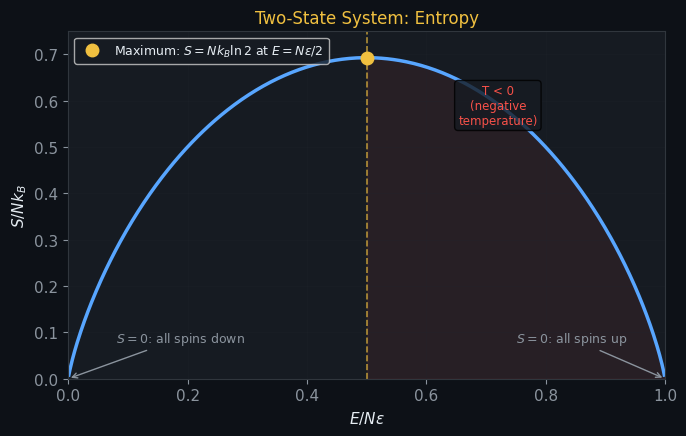

Saved: fig_two_state_entropy.png


In [2]:
# Two-state system: S(E)/Nk_B vs E/Nε
x = np.linspace(0.001, 0.999, 500)  # x = E/Nε = N_up/N
S_norm = -(x*np.log(x) + (1-x)*np.log(1-x))  # S / (N k_B)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(x, S_norm, color=BLUE, lw=2.5)
ax.axvline(0.5, color=GOLD, lw=1.2, ls='--', alpha=0.7)
ax.plot(0.5, np.log(2), 'o', color=GOLD, ms=9, zorder=5,
        label=r'Maximum: $S = Nk_B\ln 2$ at $E=N\epsilon/2$')
ax.set_xlabel(r'$E / N\epsilon$')
ax.set_ylabel(r'$S / Nk_B$')
ax.set_title('Two-State System: Entropy', color=GOLD)
ax.set_xlim(0, 1)
ax.set_ylim(0, 0.75)
ax.annotate(r'$S=0$: all spins down', xy=(0, 0), xytext=(0.08, 0.08),
            fontsize=9, color='#8b949e',
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1))
ax.annotate(r'$S=0$: all spins up', xy=(1, 0), xytext=(0.75, 0.08),
            fontsize=9, color='#8b949e',
            arrowprops=dict(arrowstyle='->', color='#8b949e', lw=1))
# Mark negative temperature region
ax.fill_between(x[x>0.5], 0, S_norm[x>0.5], alpha=0.08, color=RED)
ax.text(0.72, 0.55, 'T < 0\n(negative\ntemperature)', color=RED, fontsize=8.5,
        ha='center',
        bbox=dict(boxstyle='round,pad=0.3', facecolor='#161b22', alpha=0.8))
ax.legend(fontsize=9, loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_two_state_entropy.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved: fig_two_state_entropy.png')


## Fig 2 — Schottky Heat Capacity C(T)

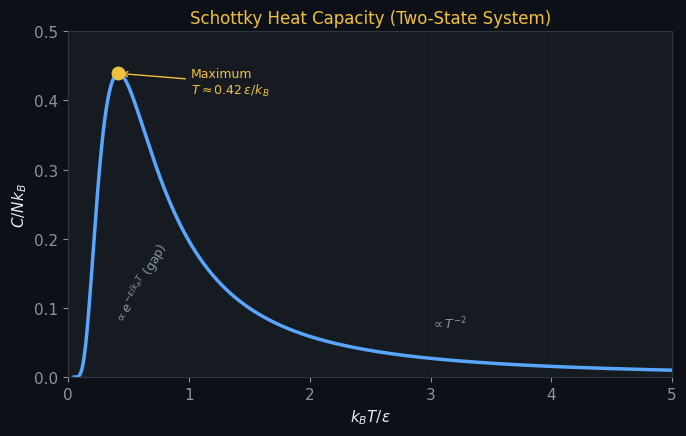

Saved: fig_two_state_heatcap.png


In [3]:
# Heat capacity of two-state system
# C/(N k_B) vs T k_B / ε
t = np.linspace(0.05, 5.0, 800)  # t = k_B T / ε
x = 1.0/t  # ε/(k_B T)
C_norm = x**2 * np.exp(x) / (np.exp(x) + 1)**2  # C/(N k_B)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(t, C_norm, color=BLUE, lw=2.5)

# Mark maximum
imax = np.argmax(C_norm)
ax.plot(t[imax], C_norm[imax], 'o', color=GOLD, ms=9, zorder=5)
ax.annotate(f'Maximum\n$T \\approx {t[imax]:.2f}\\,\\epsilon/k_B$',
            xy=(t[imax], C_norm[imax]), xytext=(t[imax]+0.6, C_norm[imax]-0.03),
            fontsize=9, color=GOLD,
            arrowprops=dict(arrowstyle='->', color=GOLD, lw=1))

# Asymptotic annotations
ax.text(0.35, 0.08, r'$\propto e^{-\epsilon/k_BT}$'+' (gap)', color='#8b949e',
        fontsize=9, rotation=60)
ax.text(3.0, 0.07, r'$\propto T^{-2}$', color='#8b949e', fontsize=9)

ax.set_xlabel(r'$k_B T / \epsilon$')
ax.set_ylabel(r'$C / Nk_B$')
ax.set_title('Schottky Heat Capacity (Two-State System)', color=GOLD)
ax.set_xlim(0, 5); ax.set_ylim(0, 0.50)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_two_state_heatcap.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved: fig_two_state_heatcap.png')


## Fig 3 — Stirling's Approximation

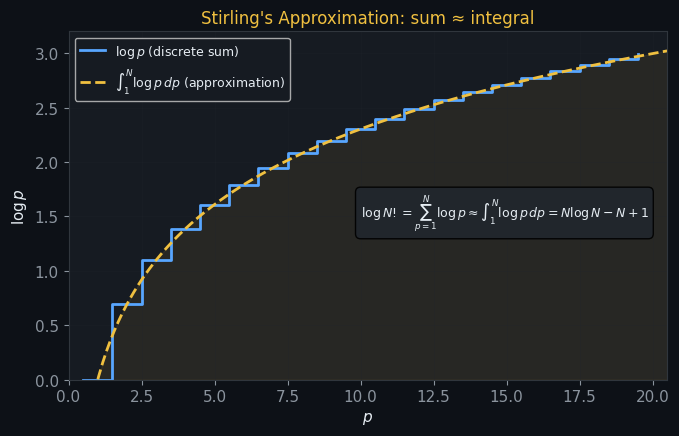

Saved: fig_stirling.png


In [4]:
# Stirling: log(p) approximated by integral
N_vals = np.arange(1, 21)
log_p  = np.log(N_vals)
x_cont = np.linspace(0.5, 20.5, 300)
log_cont = np.log(x_cont)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.step(N_vals - 0.5, log_p, where='post', color=BLUE, lw=2, label=r'$\log p$ (discrete sum)')
ax.plot(x_cont, log_cont, color=GOLD, lw=2, ls='--', label=r'$\int_1^N \log p\,dp$ (approximation)')
ax.fill_between(x_cont, log_cont, 0, alpha=0.08, color=GOLD)
ax.set_xlabel('$p$')
ax.set_ylabel(r'$\log p$')
ax.set_title("Stirling's Approximation: sum ≈ integral", color=GOLD)
ax.set_xlim(0, 20.5); ax.set_ylim(0, 3.2)
ax.text(10, 1.5,
        r'$\log N! = \sum_{p=1}^N \log p \approx \int_1^N \log p\,dp = N\log N - N + 1$',
        fontsize=9, color='#e6edf3',
        bbox=dict(boxstyle='round,pad=0.4', facecolor='#21262d', alpha=0.9))
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_stirling.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved: fig_stirling.png')


## Fig 4 — Three Ensembles: Summary Diagram

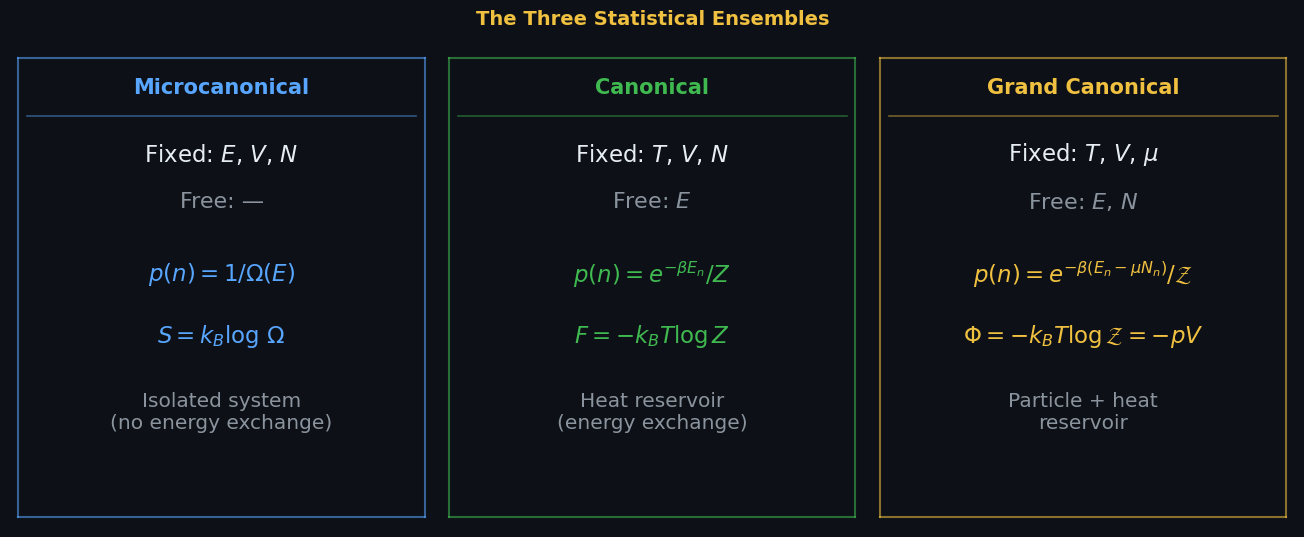

Saved: fig_ensembles_summary.png


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(13, 5.2))
fig.suptitle('The Three Statistical Ensembles', fontsize=14,
             color='#f0c040', fontweight='bold', y=1.01)
fig.patch.set_facecolor('#0d1117')

data = [
    {
        'name':  'Microcanonical',
        'color': '#58a6ff',
        'fixed': r'Fixed: $E$, $V$, $N$',
        'free':  r'Free: —',
        'prob':  r'$p(n) = 1/\Omega(E)$',
        'pot':   r'$S = k_B \log\,\Omega$',
        'desc':  'Isolated system\n(no energy exchange)',
    },
    {
        'name':  'Canonical',
        'color': '#3fb950',
        'fixed': r'Fixed: $T$, $V$, $N$',
        'free':  r'Free: $E$',
        'prob':  r'$p(n) = e^{-\beta E_n}/Z$',
        'pot':   r'$F = -k_B T \log Z$',
        'desc':  'Heat reservoir\n(energy exchange)',
    },
    {
        'name':  'Grand Canonical',
        'color': '#f0c040',
        'fixed': r'Fixed: $T$, $V$, $\mu$',
        'free':  r'Free: $E$, $N$',
        'prob':  r'$p(n) = e^{-\beta(E_n - \mu N_n)}/\mathcal{Z}$',
        'pot':   r'$\Phi = -k_BT\log\mathcal{Z} = -pV$',
        'desc':  'Particle + heat\nreservoir',
    },
]

for ax, d in zip(axes, data):
    col = d['color']
    ax.set_facecolor('#161b22')
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)
    ax.axis('off')

    # Outer border (4 lines)
    for xs, ys in [([0.02,0.98],[0.02,0.02]),([0.02,0.98],[0.98,0.98]),
                   ([0.02,0.02],[0.02,0.98]),([0.98,0.98],[0.02,0.98])]:
        ax.plot(xs, ys, color=col, lw=1.5, alpha=0.55,
                transform=ax.transAxes, clip_on=False)

    # Title
    ax.text(0.5, 0.92, d['name'], ha='center', va='center',
            fontsize=15, color=col, fontweight='bold',
            transform=ax.transAxes)
    ax.axhline(0.86, xmin=0.04, xmax=0.96, color=col, lw=1.2, alpha=0.45)

    # Rows: fixed / free / probability / potential / description
    rows = [
        (0.78, d['fixed'],  '#e6edf3', 16.5, False), #10.5
        (0.68, d['free'],   '#8b949e', 16.0, False), #10.0
        (0.53, d['prob'],   col,       16.5, True),  #10.5
        (0.40, d['pot'],    col,       16.5, True),  #10.5
        (0.24, d['desc'],   '#8b949e', 14.5, False), #9.5
    ]
    for y, txt, c, fs, use_math in rows:
        ax.text(0.5, y, txt, ha='center', va='center',
                fontsize=fs, color=c,
                transform=ax.transAxes,
                usetex=False)

plt.tight_layout(pad=0.5)
plt.savefig('fig_ensembles_summary.png', dpi=150, bbox_inches='tight',
            facecolor=fig.get_facecolor())
plt.show()
print('Saved: fig_ensembles_summary.png')


---
## Summary

| File | Used in slide |
|------|---------------|
| `fig_two_state_entropy.png` | §1.2.3 Two-State System |
| `fig_two_state_heatcap.png` | §1.2.3 Schottky Anomaly |
| `fig_stirling.png` | §1.2.3 Stirling's Formula |
| `fig_ensembles_summary.png` | Ch 1 Summary |

Copy all PNG files to `figures/` next to `statphys_ch01_slides.qmd`.


## Download — ZIP all figures

Run this cell **after** all figure cells above.
The ZIP file `statphys_ch01_figures.zip` will download automatically.

Extract into `figures/` next to `statphys_ch01_slides.qmd`.


In [6]:
import os, zipfile
from google.colab import files

# ── Collect all saved figures ──────────────────────────────────────────────────
fig_files = [
    'fig_two_state_entropy.png',
    'fig_two_state_heatcap.png',
    'fig_stirling.png',
    'fig_ensembles_summary.png',
]

zip_name = 'statphys_ch01_figures.zip'

with zipfile.ZipFile(zip_name, 'w', zipfile.ZIP_DEFLATED) as zf:
    for fname in fig_files:
        if os.path.exists(fname):
            zf.write(fname)
            print(f'  ✓ Added {fname}')
        else:
            print(f'  ✗ Missing {fname} — run the cell above first')

total_size = os.path.getsize(zip_name) / 1024
print(f'\nZIP created: {zip_name}  ({total_size:.1f} KB)')
print('Starting download...')
files.download(zip_name)


  ✓ Added fig_two_state_entropy.png
  ✓ Added fig_two_state_heatcap.png
  ✓ Added fig_stirling.png
  ✓ Added fig_ensembles_summary.png

ZIP created: statphys_ch01_figures.zip  (261.1 KB)
Starting download...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>